## Step 1: Install and import libraries

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")


Libraries imported successfully!


## Step 2: Load CSV files from Google Drive

In [2]:
# Google Drive File IDs
agents_id = "1qv_qdMYLkqt7mC5JKccAvOBgX0Zzvkic"
callers_id = "1BuX5khZnf_GDCcbNWx4dWAvQCCq4Nebc"
calls_id = "1izeHRkI76QsPyza_ug0RhtGgzk_9Lgeq"
queues_id = "108Tqg_C_RMtmaMc0JRT0RG1bmrHnWKC8"

# Load datasets
base_url = "https://drive.google.com/uc?export=download&id="

agents = pd.read_csv(base_url + agents_id)
callers = pd.read_csv(base_url + callers_id)
calls = pd.read_csv(base_url + calls_id)
queues = pd.read_csv(base_url + queues_id)

print("All four datasets loaded successfully!")


All four datasets loaded successfully!


## Step 3: Inspect the Datasets

In [3]:
datasets = {
    "Agents": agents,
    "Callers": callers,
    "Calls": calls,
    "Queues": queues
}

for name, df in datasets.items():
    print(f"\n{'='*50}")
    print(f"DATASET: {name}")
    print(f"Shape: {df.shape}")
    print("\nColumns:")
    print(df.columns.tolist())
    print("\nMissing values:")
    print(df.isnull().sum())
    print("\nDuplicate rows:", df.duplicated().sum())
    display(df.head())



DATASET: Agents
Shape: (30, 6)

Columns:
['id', 'first_name', 'last_name', 'team', 'tenure_months', 'speed_factor']

Missing values:
id               0
first_name       0
last_name        0
team             0
tenure_months    0
speed_factor     0
dtype: int64

Duplicate rows: 0


,id,first_name,last_name,team,tenure_months,speed_factor
0,1,Cynthia,McLaughlin,Team North,62,1.01
1,2,Edyth,Lockman,Team North,31,1.09
2,3,Lupe,Kertzmann-Brekke,Team North,12,1.19
3,4,Lloyd,Bergnaum,Team South,2,0.96
4,5,Earnest,Bednar,Team North,63,0.96



DATASET: Callers
Shape: (250, 4)

Columns:
['id', 'caller_ref', 'account_type', 'region']

Missing values:
id              0
caller_ref      0
account_type    0
region          0
dtype: int64

Duplicate rows: 0


,id,caller_ref,account_type,region
0,1,CL-696409,consumer,West
1,2,CL-330627,consumer,North
2,3,CL-501041,consumer,South
3,4,CL-726161,consumer,East
4,5,CL-669474,small_business,South



DATASET: Calls
Shape: (800, 13)

Columns:
['id', 'queue_id', 'caller_id', 'started_at', 'status', 'base_wait_seconds', 'wait_seconds', 'abandon_after_seconds', 'agent_id', 'base_handle_seconds', 'queue_handle_seconds', 'handle_seconds', 'resolved_first_contact']

Missing values:
id                          0
queue_id                    0
caller_id                   0
started_at                  0
status                      0
base_wait_seconds         105
wait_seconds              105
abandon_after_seconds     695
agent_id                  105
base_handle_seconds       105
queue_handle_seconds      105
handle_seconds            105
resolved_first_contact    105
dtype: int64

Duplicate rows: 0


,id,queue_id,caller_id,started_at,status,base_wait_seconds,wait_seconds,abandon_after_seconds,agent_id,base_handle_seconds,queue_handle_seconds,handle_seconds,resolved_first_contact
0,1,3,104,2/27/25 11:33,answered,16.0,19.0,NaN,27.0,143.0,157.0,157.0,True
1,2,1,1,2/5/25 19:44,answered,13.0,8.0,NaN,10.0,151.0,106.0,112.0,True
2,3,3,88,2/5/25 19:44,answered,26.0,31.0,NaN,19.0,121.0,133.0,145.0,True
3,4,2,141,2/3/25 9:01,answered,24.0,22.0,NaN,12.0,143.0,129.0,125.0,True
4,5,4,73,2/11/25 12:04,answered,10.0,15.0,NaN,27.0,166.0,216.0,216.0,True



DATASET: Queues
Shape: (5, 6)

Columns:
['id', 'queue_set', 'queue_name', 'sla_seconds', 'wait_factor', 'handle_factor']

Missing values:
id               0
queue_set        0
queue_name       0
sla_seconds      0
wait_factor      0
handle_factor    0
dtype: int64

Duplicate rows: 0


,id,queue_set,queue_name,sla_seconds,wait_factor,handle_factor
0,1,1,Billing,30,0.6,0.7
1,2,1,Account changes,30,0.9,0.9
2,3,1,Sales,30,1.2,1.1
3,4,1,Technical support,30,1.5,1.3
4,5,1,Complaints,30,1.8,1.5


## Step 4: Inspect the missing values

In [4]:
# 1. Check call status distribution
print("CALL STATUS DISTRIBUTION")
display(calls['status'].value_counts(dropna=False))

# 2. Check missing values by call status
print("\nMISSING VALUES BY CALL STATUS")
missing_by_status = calls.groupby('status').agg(
    total_calls=('id', 'count'),
    missing_agent=('agent_id', lambda x: x.isna().sum()),
    missing_wait=('wait_seconds', lambda x: x.isna().sum()),
    missing_handle=('handle_seconds', lambda x: x.isna().sum()),
    missing_abandon_time=('abandon_after_seconds', lambda x: x.isna().sum())
)

display(missing_by_status)

# 3. Check whether IDs are unique
print("\nID UNIQUENESS")
print("Unique call IDs:", calls['id'].nunique())
print("Unique agent IDs:", agents['id'].nunique())
print("Unique caller IDs:", callers['id'].nunique())
print("Unique queue IDs:", queues['id'].nunique())

# 4. Check date range
calls['started_at'] = pd.to_datetime(
    calls['started_at'], errors='coerce'
)

print("\nCALL DATE RANGE")
print("Start:", calls['started_at'].min())
print("End:", calls['started_at'].max())

# 5. Check categorical values
print("\nCALL STATUS VALUES:")
print(calls['status'].unique())

print("\nAGENT TEAMS:")
print(agents['team'].value_counts())

print("\nQUEUE NAMES:")
print(queues['queue_name'].tolist())


CALL STATUS DISTRIBUTION


,count
status,
answered,695
abandoned,105



MISSING VALUES BY CALL STATUS


,total_calls,missing_agent,missing_wait,missing_handle,missing_abandon_time
status,,,,,
abandoned,105,105,105,105,0
answered,695,0,0,0,695



ID UNIQUENESS
Unique call IDs: 800
Unique agent IDs: 30
Unique caller IDs: 250
Unique queue IDs: 5

CALL DATE RANGE
Start: 2025-02-03 00:05:00
End: 2025-02-28 23:15:00

CALL STATUS VALUES:
['answered' 'abandoned']

AGENT TEAMS:
team
Team South    13
Team North    10
Team East      7
Name: count, dtype: int64

QUEUE NAMES:
['Billing', 'Account changes', 'Sales', 'Technical support', 'Complaints']


## Step 5. Data cleaning and master dataset creation

In [5]:
# 1. Create working copies
calls_clean = calls.copy()
agents_clean = agents.copy()
callers_clean = callers.copy()
queues_clean = queues.copy()

# 2. Rename primary IDs
calls_clean.rename(columns={'id': 'call_id'}, inplace=True)
agents_clean.rename(columns={'id': 'agent_key'}, inplace=True)
callers_clean.rename(columns={'id': 'caller_key'}, inplace=True)
queues_clean.rename(columns={'id': 'queue_key'}, inplace=True)

# 3. Convert timestamp
calls_clean['started_at'] = pd.to_datetime(
    calls_clean['started_at'], errors='coerce'
)

# 4. Convert numeric columns
numeric_cols = [
    'queue_id', 'caller_id', 'agent_id',
    'base_wait_seconds', 'wait_seconds',
    'abandon_after_seconds', 'base_handle_seconds',
    'queue_handle_seconds', 'handle_seconds'
]

for col in numeric_cols:
    calls_clean[col] = pd.to_numeric(
        calls_clean[col], errors='coerce'
    )

# 5. Merge all four datasets
master = calls_clean.merge(
    queues_clean,
    left_on='queue_id',
    right_on='queue_key',
    how='left'
)

master = master.merge(
    agents_clean,
    left_on='agent_id',
    right_on='agent_key',
    how='left'
)

master = master.merge(
    callers_clean,
    left_on='caller_id',
    right_on='caller_key',
    how='left'
)

# 6. Create time-based features
master['call_date'] = master['started_at'].dt.date
master['call_hour'] = master['started_at'].dt.hour
master['day_of_week'] = master['started_at'].dt.day_name()
master['day_of_week_num'] = master['started_at'].dt.dayofweek

# 7. Create operational indicators
master['answered_flag'] = (
    master['status'] == 'answered'
).astype(int)

master['abandoned_flag'] = (
    master['status'] == 'abandoned'
).astype(int)

master['sla_met'] = np.where(
    master['status'] == 'answered',
    (master['wait_seconds'] <= master['sla_seconds']).astype(int),
    np.nan
)

# 8. Rename important columns
master.rename(columns={
    'queue_name': 'queue',
    'tenure_months': 'agent_tenure_months',
    'speed_factor': 'agent_speed_factor',
    'first_name': 'agent_first_name',
    'last_name': 'agent_last_name'
}, inplace=True)

# 9. Verify master dataset
print("MASTER DATASET CREATED")
print("Shape:", master.shape)
print("Total calls:", len(master))
print("\nCall status:")
print(master['status'].value_counts())

print("\nMissing values:")
print(master.isnull().sum())

print("\nMaster dataset preview:")
display(master.head())

MASTER DATASET CREATED
Shape: (800, 36)
Total calls: 800

Call status:
status
answered     695
abandoned    105
Name: count, dtype: int64

Missing values:
call_id                     0
queue_id                    0
caller_id                   0
started_at                  0
status                      0
base_wait_seconds         105
wait_seconds              105
abandon_after_seconds     695
agent_id                  105
base_handle_seconds       105
queue_handle_seconds      105
handle_seconds            105
resolved_first_contact    105
queue_key                   0
queue_set                   0
queue                       0
sla_seconds                 0
wait_factor                 0
handle_factor               0
agent_key                 105
agent_first_name          105
agent_last_name           105
team                      105
agent_tenure_months       105
agent_speed_factor        105
caller_key                  0
caller_ref                  0
account_type                0
regio

,call_id,queue_id,caller_id,started_at,status,base_wait_seconds,wait_seconds,abandon_after_seconds,agent_id,base_handle_seconds,queue_handle_seconds,handle_seconds,resolved_first_contact,queue_key,queue_set,queue,sla_seconds,wait_factor,handle_factor,agent_key,agent_first_name,agent_last_name,team,agent_tenure_months,agent_speed_factor,caller_key,caller_ref,account_type,region,call_date,call_hour,day_of_week,day_of_week_num,answered_flag,abandoned_flag,sla_met
0,1,3,104,2025-02-27 11:33:00,answered,16.0,19.0,NaN,27.0,143.0,157.0,157.0,True,3,1,Sales,30,1.2,1.1,27.0,Michale,Grimes,Team East,82.0,1.00,104,CL-960645,consumer,North,2025-02-27,11,Thursday,3,1,0,1.0
1,2,1,1,2025-02-05 19:44:00,answered,13.0,8.0,NaN,10.0,151.0,106.0,112.0,True,1,1,Billing,30,0.6,0.7,10.0,Darryl,Becker,Team South,15.0,1.06,1,CL-696409,consumer,West,2025-02-05,19,Wednesday,2,1,0,1.0
2,3,3,88,2025-02-05 19:44:00,answered,26.0,31.0,NaN,19.0,121.0,133.0,145.0,True,3,1,Sales,30,1.2,1.1,19.0,Manuel,Weissnat,Team East,7.0,1.09,88,CL-799007,consumer,East,2025-02-05,19,Wednesday,2,1,0,0.0
3,4,2,141,2025-02-03 09:01:00,answered,24.0,22.0,NaN,12.0,143.0,129.0,125.0,True,2,1,Account changes,30,0.9,0.9,12.0,Valerie,Auer,Team North,58.0,0.97,141,CL-959730,small_business,South,2025-02-03,9,Monday,0,1,0,1.0
4,5,4,73,2025-02-11 12:04:00,answered,10.0,15.0,NaN,27.0,166.0,216.0,216.0,True,4,1,Technical support,30,1.5,1.3,27.0,Michale,Grimes,Team East,82.0,1.00,73,CL-054765,consumer,North,2025-02-11,12,Tuesday,1,1,0,1.0


## Step 6: Validate the joins

In [6]:
# Join validation
print("CALLS:", len(calls_clean))
print("MASTER RECORDS:", len(master))

print("\nUnmatched queue records:",
      master['queue'].isna().sum())

print("Unmatched agent records among answered calls:",
      master.loc[
          master['status'] == 'answered', 'agent_first_name'
      ].isna().sum())

print("Unmatched caller records:",
      master['caller_ref'].isna().sum())

print("\nUnique call IDs:", master['call_id'].nunique())
print("Duplicate call IDs:", master['call_id'].duplicated().sum())

assert len(master) == 800
assert master['call_id'].nunique() == 800
assert master['queue'].notna().all()

print("\nAll validation checks passed!")


CALLS: 800
MASTER RECORDS: 800

Unmatched queue records: 0
Unmatched agent records among answered calls: 0
Unmatched caller records: 0

Unique call IDs: 800
Duplicate call IDs: 0

All validation checks passed!


## Step 7: Core WFM KPI Calculations

In [7]:
# Separate answered and abandoned calls
answered = master[master['status'] == 'answered'].copy()
abandoned = master[master['status'] == 'abandoned'].copy()

# Calculate KPIs
total_calls = len(master)
total_answered = len(answered)
total_abandoned = len(abandoned)

abandonment_rate = (total_abandoned / total_calls) * 100

aht = answered['handle_seconds'].mean()
awt = answered['wait_seconds'].mean()

sla_attainment = (
    (answered['wait_seconds'] <= answered['sla_seconds']).mean()
    * 100
)

fcr_rate = answered['resolved_first_contact'].mean() * 100

# Create KPI summary
kpi_summary = pd.DataFrame({
    'KPI': [
        'Total Calls',
        'Answered Calls',
        'Abandoned Calls',
        'Abandonment Rate (%)',
        'Average Handling Time (seconds)',
        'Average Waiting Time (seconds)',
        'Answered-call SLA Attainment (%)',
        'First Call Resolution (%)'
    ],
    'Value': [
        total_calls,
        total_answered,
        total_abandoned,
        round(abandonment_rate, 2),
        round(aht, 2),
        round(awt, 2),
        round(sla_attainment, 2),
        round(fcr_rate, 2)
    ]
})

display(kpi_summary)

# Print formatted results
print("\nWFM PERFORMANCE SUMMARY")
print("-" * 40)
print(f"Total Calls: {total_calls}")
print(f"Answered Calls: {total_answered}")
print(f"Abandoned Calls: {total_abandoned}")
print(f"Abandonment Rate: {abandonment_rate:.2f}%")
print(f"Average Handling Time: {aht:.2f} seconds")
print(f"Average Waiting Time: {awt:.2f} seconds")
print(f"Answered-call SLA Attainment: {sla_attainment:.2f}%")
print(f"First Call Resolution: {fcr_rate:.2f}%")


,KPI,Value
0,Total Calls,800.00
1,Answered Calls,695.00
2,Abandoned Calls,105.00
3,Abandonment Rate (%),13.12
4,Average Handling Time (seconds),217.39
5,Average Waiting Time (seconds),24.81
6,Answered-call SLA Attainment (%),73.24
7,First Call Resolution (%),73.53



WFM PERFORMANCE SUMMARY
----------------------------------------
Total Calls: 800
Answered Calls: 695
Abandoned Calls: 105
Abandonment Rate: 13.12%
Average Handling Time: 217.39 seconds
Average Waiting Time: 24.81 seconds
Answered-call SLA Attainment: 73.24%
First Call Resolution: 73.53%


## Step 8: Analyze Demand Pattern

,call_hour,total_calls,answered_calls,abandoned_calls
0,0,2,2,0
1,1,1,1,0
2,2,1,1,0
3,3,3,3,0
4,4,1,0,1
5,5,3,3,0
6,6,3,2,1
7,7,12,9,3
8,8,42,39,3
9,9,63,58,5


,queue,total_calls,answered_calls,abandoned_calls,avg_wait,avg_handle,abandonment_rate
0,Account changes,128,110,18,21.17,185.88,14.06
1,Billing,207,182,25,13.36,139.87,12.08
2,Complaints,86,72,14,37.12,322.38,16.28
3,Sales,156,131,25,25.62,216.71,16.03
4,Technical support,223,200,23,32.27,267.92,10.31


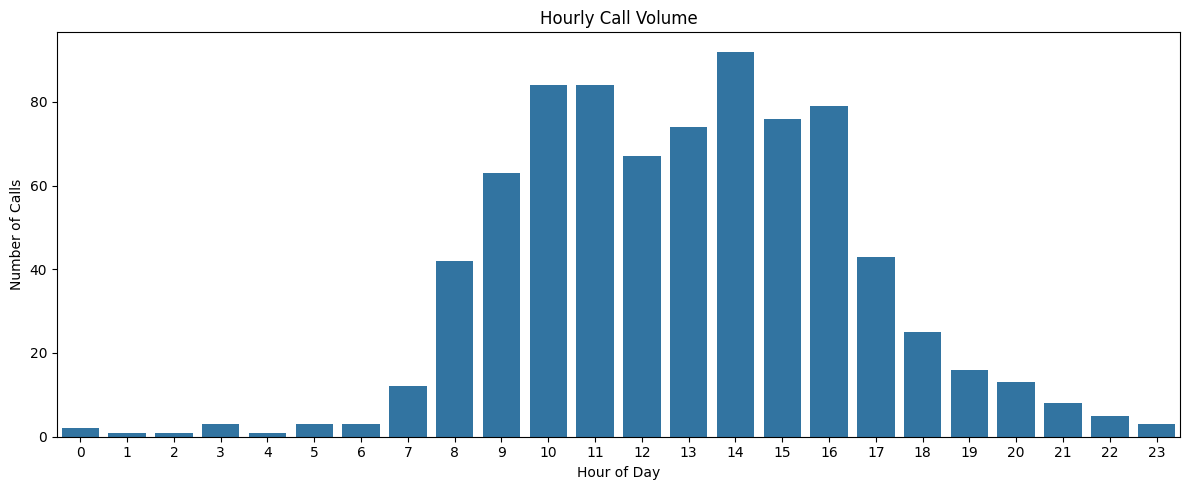

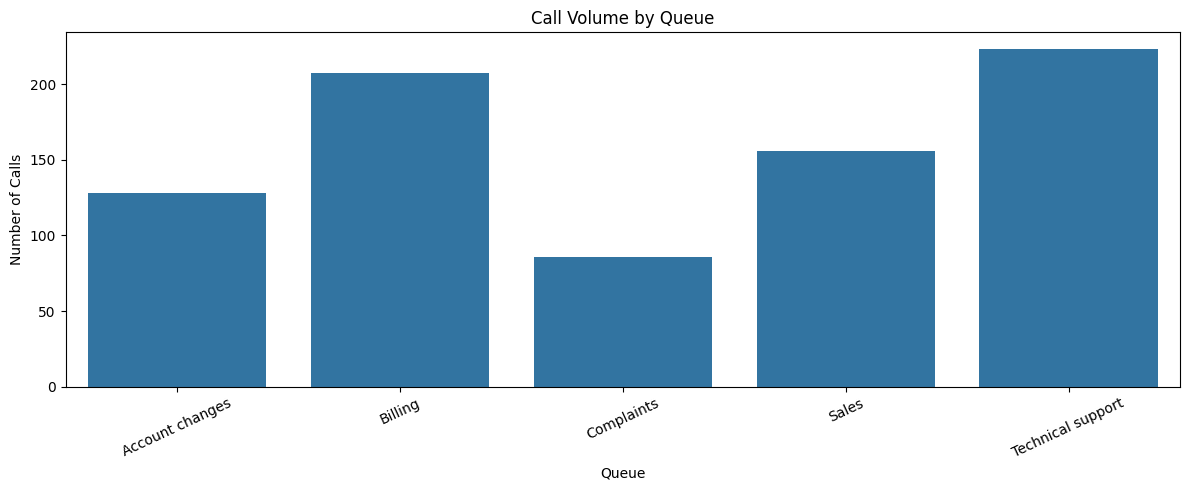

In [8]:
# Hourly call volume
hourly_volume = (
    master.groupby('call_hour')
    .agg(
        total_calls=('call_id', 'count'),
        answered_calls=('answered_flag', 'sum'),
        abandoned_calls=('abandoned_flag', 'sum')
    )
    .reset_index()
)

display(hourly_volume)

# Queue-wise performance
queue_performance = (
    master.groupby('queue')
    .agg(
        total_calls=('call_id', 'count'),
        answered_calls=('answered_flag', 'sum'),
        abandoned_calls=('abandoned_flag', 'sum'),
        avg_wait=('wait_seconds', 'mean'),
        avg_handle=('handle_seconds', 'mean')
    )
    .reset_index()
)

queue_performance['abandonment_rate'] = (
    queue_performance['abandoned_calls'] /
    queue_performance['total_calls'] * 100
)

display(queue_performance.round(2))

# Visualise hourly demand
plt.figure(figsize=(12, 5))
sns.barplot(
    data=hourly_volume,
    x='call_hour',
    y='total_calls'
)
plt.title('Hourly Call Volume')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Calls')
plt.tight_layout()
plt.show()

# Visualise queue demand
plt.figure(figsize=(12, 5))
sns.barplot(
    data=queue_performance,
    x='queue',
    y='total_calls'
)
plt.title('Call Volume by Queue')
plt.xlabel('Queue')
plt.ylabel('Number of Calls')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


Interpret the results
Three findings stand out:
1. Peak demand: 2 PM has the highest call volume (92 calls), followed by 10 AM and 11 AM (84 each).
2. Queue pressure: Complaints has the highest average waiting time (37.12 seconds), highest AHT (322.38 seconds) and highest abandonment rate (16.28%).
3. Technical Support: It receives the most calls (223), but its abandonment rate is relatively low at 10.31%.
Our overall answered-call SLA attainment is 73.24%, against a 30-second threshold. This indicates room for operational improvement.

One distinction: high call volume does not automatically mean inadequate staffing. We'll need to examine workload and estimated staffing requirements before making that recommendation.

## Step 9: Workforce capacity and staffing analysis

Observed days: 26


,call_hour,answered_calls,total_handle_seconds,workload_hours,avg_daily_workload_hours,required_agents,required_agents_rounded
0,0,2,547.0,0.15,0.01,0.01,1
1,1,1,350.0,0.10,0.00,0.01,1
2,2,1,251.0,0.07,0.00,0.00,1
3,3,3,557.0,0.15,0.01,0.01,1
4,5,3,605.0,0.17,0.01,0.01,1
5,6,2,375.0,0.10,0.00,0.01,1
6,7,9,1456.0,0.40,0.02,0.03,1
7,8,39,9602.0,2.67,0.10,0.17,1
8,9,58,12789.0,3.55,0.14,0.23,1
9,10,75,15707.0,4.36,0.17,0.28,1



WORKFORCE CAPACITY SUMMARY
Peak hour: 16.0
Peak estimated staffing: 1.0


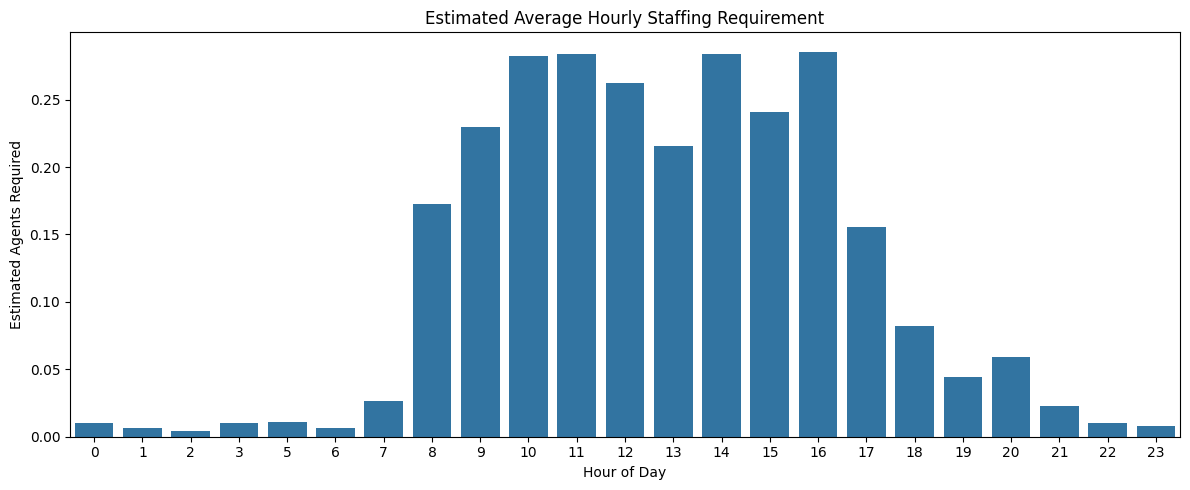

In [9]:
# Planning assumptions
TARGET_OCCUPANCY = 0.85
SHRINKAGE = 0.30

# Number of observed calendar days
total_days = master['call_date'].nunique()

print("Observed days:", total_days)

# Calculate hourly workload from answered calls
hourly_workload = (
    answered.groupby('call_hour')
    .agg(
        answered_calls=('call_id', 'count'),
        total_handle_seconds=('handle_seconds', 'sum')
    )
    .reset_index()
)

# Convert workload into hours
hourly_workload['workload_hours'] = (
    hourly_workload['total_handle_seconds'] / 3600
)

# Average workload per day for each hour
hourly_workload['avg_daily_workload_hours'] = (
    hourly_workload['workload_hours'] / total_days
)

# Estimate required staffing
hourly_workload['required_agents'] = (
    hourly_workload['avg_daily_workload_hours'] /
    (TARGET_OCCUPANCY * (1 - SHRINKAGE))
)

hourly_workload['required_agents_rounded'] = (
    np.ceil(hourly_workload['required_agents'])
).astype(int)

display(hourly_workload.round(2))

# Peak staffing requirement
peak_hour = hourly_workload.loc[
    hourly_workload['required_agents'].idxmax()
]

print("\nWORKFORCE CAPACITY SUMMARY")
print("Peak hour:", peak_hour['call_hour'])
print("Peak estimated staffing:",
      peak_hour['required_agents_rounded'])

# Staffing requirement chart
plt.figure(figsize=(12, 5))

sns.barplot(
    data=hourly_workload,
    x='call_hour',
    y='required_agents'
)

plt.title('Estimated Average Hourly Staffing Requirement')
plt.xlabel('Hour of Day')
plt.ylabel('Estimated Agents Required')
plt.tight_layout()
plt.show()


Key findings:

1. Peak workload occurs at 4 PM (16:00). The highest estimated workload is 4.42 hours of agent handling time across the 26 observed days. This is followed by 10 AM, 11 AM and 2 PM, each with approximately 4.36–4.39 workload hours.

2. The busiest operational window is 10 AM–4 PM. These hours consistently account for the highest handling workload, indicating that workforce scheduling should pay particular attention to this period.

3. Estimated staffing requirement is low when averaged across all 26 days. Under the assumptions of 85% occupancy and 30% shrinkage, the peak-hour estimate is approximately 0.29 agents, which rounds up to one agent.

4. The rounded estimate should not be interpreted as actual staffing capacity. It is an average workload-based estimate, not a measure of the number of agents required simultaneously to meet the SLA. It does not account for arrival patterns within each hour, concurrent calls, shift schedules or real-time availability.

Business implication: Workforce scheduling should align agent availability with the concentration of demand during the 10 AM–4 PM period. A more detailed interval-level analysis would be required before making actual staffing decisions.
Step 14: Queue-level workload analysis
This analysis compares the handling workload distributed across the five customer-service queues.

## Step 10. Queue-level workload analysis

,queue,answered_calls,total_handle_seconds,avg_handle_seconds,total_workload_hours,workload_share_pct,avg_daily_workload_hours,avg_daily_staffing_estimate
0,Account changes,110,20447.0,185.88,5.68,13.53,0.22,0.37
1,Billing,182,25457.0,139.87,7.07,16.85,0.27,0.46
2,Complaints,72,23211.0,322.38,6.45,15.36,0.25,0.42
3,Sales,131,28389.0,216.71,7.89,18.79,0.30,0.51
4,Technical support,200,53583.0,267.92,14.88,35.46,0.57,0.96


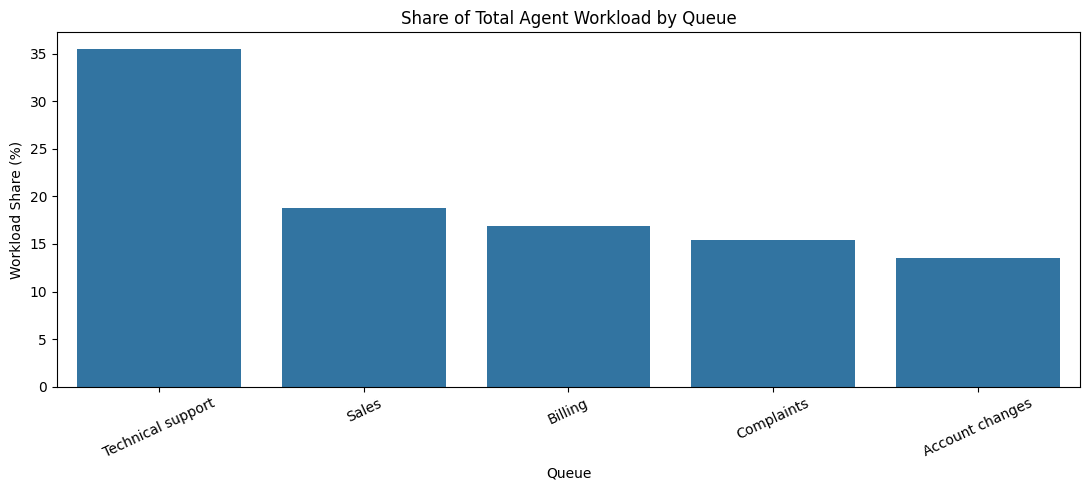

In [10]:
queue_workload = (
    answered.groupby('queue')
    .agg(
        answered_calls=('call_id', 'count'),
        total_handle_seconds=('handle_seconds', 'sum'),
        avg_handle_seconds=('handle_seconds', 'mean')
    )
    .reset_index()
)

queue_workload['total_workload_hours'] = (
    queue_workload['total_handle_seconds'] / 3600
)

queue_workload['workload_share_pct'] = (
    queue_workload['total_workload_hours'] /
    queue_workload['total_workload_hours'].sum() * 100
)

queue_workload['avg_daily_workload_hours'] = (
    queue_workload['total_workload_hours'] / total_days
)

queue_workload['avg_daily_staffing_estimate'] = (
    queue_workload['avg_daily_workload_hours'] /
    (TARGET_OCCUPANCY * (1 - SHRINKAGE))
)

display(queue_workload.round(2))

# Visualise workload distribution
plt.figure(figsize=(11, 5))

sns.barplot(
    data=queue_workload.sort_values(
        'workload_share_pct', ascending=False
    ),
    x='queue',
    y='workload_share_pct'
)

plt.title('Share of Total Agent Workload by Queue')
plt.xlabel('Queue')
plt.ylabel('Workload Share (%)')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

Key findings:

1. Technical Support contributes the highest workload. It accounts for 35.46% of total handling workload, with 200 answered calls and 14.88 total workload hours. It is the largest contributor to operational demand.

2. Sales is the second-largest workload contributor. It represents 18.79% of total workload, followed by Billing at 16.85%.

3. Complaints has the highest average handling time. At 322.38 seconds per call, it requires substantially more handling time per answered call than the other queues. This suggests that complaint-related interactions may involve more complex customer issues.

4. Technical Support also has a relatively high average handling time. Its average is 267.92 seconds, making it the second-highest among the five queues.

5. Technical Support has the highest estimated average daily staffing requirement. Its estimate is 0.96 agents, compared with 0.51 for Sales, 0.46 for Billing, 0.42 for Complaints and 0.37 for Account Changes.

Business implication: Technical Support deserves priority when allocating workforce capacity because it contributes the largest share of total workload. Complaints may also require attention because of its high average handling time. Staffing decisions should consider both call volume and handling complexity, rather than call volume alone.

## SQL Analysis

In [11]:
# Export cleaned master dataset for SQL analysis
master.to_csv("wfm_master_calls.csv", index=False)

print("Export complete:", master.shape)


Export complete: (800, 36)


In [12]:
from google.colab import files

files.download('wfm_master_calls.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>